# 03a Compare: per-element verdicts for the CRAS room, against the real model

**Slice.** One room of the CRAS lab ("room B", the box recorded in `01_cras_slice.json`): the 1 cm scan cache cut to that box, and the 35 model elements that touch the box. Furniture and proxies are clutter and never get a verdict.

**Question.** Starting from notebook 01's recorded transform, what does each of the 35 elements get (OK, shifted, not confirmed) at the USIBD LOA30 tolerance, and how much does it matter whether the scan classes (oracle labels) are used to separate clutter from elements?

Sections: (1) load, (2) frame: a coarse check of the recorded transform, then ICP refinement and the correction it makes, (3) comparison per element, (4) with vs without oracle labels, (5) outputs, then the answer.
Terms (scan, model, element, clutter, scan class, oracle labels, registration residual, tolerance, verdict) are defined in [CONTEXT.md](../CONTEXT.md).
All randomness is seeded. Nothing is written outside `outputs/03a/` (gitignored).

In [1]:
import csv, json, os, resource, time
from pathlib import Path
from types import SimpleNamespace

import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
import numpy as np

os.environ["OPEN3D_DISABLE_WEB_VISUALIZER"] = "true"  # before the import: skips Open3D's Jupyter web-visualizer banner
import open3d as o3d
from IPython.display import Image, display

from scan_vs_bim.load import load_ifc_elements, merge_meshes

%config InlineBackend.figure_format = 'png'
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 100, "font.size": 9})
o3d.utility.set_verbosity_level(o3d.utility.VerbosityLevel.Error)
reg = o3d.pipelines.registration

# All parameters in one place. Lengths in metres. Judgement calls are marked (not from a standard).
SEED = 0
CRAS = Path("../data/cras")
CACHE, IFC = CRAS / "cras_voxel_1cm.npz", CRAS / "craslabbim.ifc"
SLICE = Path("01_cras_slice.json")  # written by notebook 01: recorded transform, room box, the 35 elements
OUT = Path("../outputs/03a")  # gitignored; never write outside outputs/
OUT.mkdir(parents=True, exist_ok=True)

# Scan classes (index = class id in the cache) and the ones the model has elements for (the rest is clutter)
CLASS_NAMES = ["unassigned", "ceiling", "floor", "wall", "door", "window", "desk", "chair", "cabinet", "mobile cabinet",
               "shelf", "vents", "water tank", "bin", "box", "board", "computer", "screen", "printer", "vest", "switch",
               "paper dispenser", "alcohol dispenser", "cable", "phone", "robot", "water kettle", "stairs", "ladder",
               "oil heater", "divider", "hanger", "fan", "water dispenser"]
ELEMENT_SCAN_CLASSES = ("ceiling", "floor", "wall", "door", "window", "stairs")
ELEMENT_CLASSES = ("IfcWallStandardCase", "IfcColumn", "IfcDoor", "IfcWindow", "IfcSlab", "IfcCovering", "IfcStairFlight")  # 01's list

# Comparison
TOL = 0.015  # USIBD LOA30: at most 15 mm at 2 sigma (95 %); quoted in section 3
BAND = 0.10  # (judgement call) scan points further than this from every element surface are ignored; the same as 00
PAD = BAND  # (judgement call) the room box is padded by this much when cropping, see section 3 for why
MIN_POINTS = 2000  # (judgement call) 1 cm voxels give one point per cm2, so 2000 points is about 0.2 m2 (a 45 cm square) of scanned surface
MIN_FRAC_OK = 0.95  # LOA30 is "specified at the 95 % confidence level": 15 mm is at 2 sigma, so 95 % of an element's points must lie within it
                    # (00's toy used 0.8; section 4 shows that value too)
MIN_FRAC_CLUSTER = 0.8  # (judgement call, not from the standard) shifted: share of points within TOL of the element's median. Clutter and element edges
                        # leave a real offset plane only 78 to 94 % near its median on this room, so 95 % is too strict here; 0.8 still rejects a 55/45 bimodal wall
SIDE_NEAR, SIDE_FAR, SIDE_STEP = 0.03, 0.20, 0.02  # (judgement call) wall side test: look this far from a wall point along the thickness axis: beyond the point's own surface noise,
                                                    # past a 10 cm drywall's other face, short of most furniture. Steps are one occupancy voxel
OCC_VOXEL = 0.02  # (judgement call) occupancy grid voxel for the side test: 2 cm, about 35 MB as a dense bool array over the crop
VOTE_BIN = 0.005  # plane vote: 5 mm bins along the thickness axis; the window is TOL each side (VOTE_HALF bins)
VOTE_HALF = round(TOL / VOTE_BIN)
VOTE_SHARE = 0.5  # (judgement call) a plane takes the side that more than half of all its points show by themselves; 03a's section 3 gives the reason
MIN_AREA_IN_BOX = 0.10  # (judgement call) below this share of an element's surface inside the room box, the in-box part is too small to stand for the element

# Frame: coarse check (FPFH + RANSAC as in 02), then ICP refinement
N_MODEL_SAMPLES, MODEL_CLIP = 3_000_000, 0.3  # points sampled on the 35 elements; kept within this margin of the box
VOXEL = 0.10  # (judgement call) 02 uses 0.8 % of the model diagonal; the room is about 12 m across
NORMAL_RADIUS, FPFH_RADIUS = 2 * VOXEL, 5 * VOXEL
RANSAC_DIST, RANSAC_ITERS, RANSAC_CONFIDENCE = 1.5 * VOXEL, 1_000_000, 0.999
RANSAC_SEEDS = (0, 1, 2, 3, 4)
ICP_DIST = 0.10  # plain point-to-plane ICP; the same as 00
ICP_FINE_DIST, TUKEY_K = 0.05, 0.02  # robust pass: Tukey loss gives residuals beyond 2 cm no weight; the same as 00
# Sanity bounds on the ICP correction, not a standard: 01 fitted the recorded transform on the same surfaces, so a refinement that
# moves the room by more than 5 cm (3x the tolerance) or turns it by more than 0.5 deg (3.5 cm at 4 m) has found something else.
SANITY_ROT_DEG, SANITY_TRANS_M = 0.5, 0.05

T0 = time.time()
def peak_rss_gb():
    return resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e9  # bytes on macOS


def apply(T, p):
    # Rigid transform T (4x4) applied to points p (n, 3); float32 in, float32 out.
    return (p @ T[:3, :3].T.astype(np.float32) + T[:3, 3].astype(np.float32)).astype(np.float32)

## 1. Load: the 35 room elements, then the scan cut to the room

The inputs are the contract written by notebook 01: `frame.scan_to_model_4x4` (apply it to scan points to get the model frame), `room.box_model_frame` (in the model frame), the 35 element GlobalIds with `inside_box`, and `scanner_positions.recovered`.

Only the 35 elements are tessellated (`load_ifc_elements(..., only_guids=...)`), which takes seconds instead of minutes. The scan cache is transformed in chunks and cropped at once, and the full arrays are deleted, to keep the peak low. The crop is the box **padded by `PAD`** on every side (why: section 3); `in_box` marks the points inside the box itself.

In [2]:
slice_ = json.loads(SLICE.read_text())
ROOM, FRAME = slice_["room"], slice_["frame"]
T_REC = np.array(FRAME["scan_to_model_4x4"])  # scan frame -> model frame, as recorded by 01
BOX = ROOM["box_model_frame"]
box_lo = np.array([BOX[k] for k in ("xmin", "ymin", "zmin")])
box_hi = np.array([BOX[k] for k in ("xmax", "ymax", "zmax")])
GUIDS = ROOM["element_global_ids"]
META = {e["global_id"]: e for e in ROOM["elements"]}
print(f"01: frame answer {FRAME['answer']!r} (as delivered), recorded transform yaw {FRAME['yaw_deg']:.2f} deg, tilt {FRAME['tilt_deg']:.2f} deg, "
      f"translation {np.round(FRAME['translation_m'], 3)} m")
print(f"01: scanner positions recovered: {slice_['scanner_positions']['recovered']} "
      f"({slice_['scanner_positions']['n_found']} of {slice_['scanner_positions']['n_expected']}, none inside the room box)")

t = time.time()
by_id = {e.global_id: e for e in load_ifc_elements(IFC, only_guids=GUIDS)}  # tessellation first: it has the higher memory peak
assert set(by_id) == set(GUIDS) and len(GUIDS) == 35, "not all 35 room elements were found in the IFC"
elements = [by_id[g] for g in GUIDS]
assert all(e.ifc_class in ELEMENT_CLASSES and e.ifc_class == META[e.global_id]["ifc_class"] for e in elements)
print(f"\n{len(elements)} elements tessellated in {time.time() - t:.0f} s, {sum(len(e.faces) for e in elements):,} triangles")
for c in ELEMENT_CLASSES:
    print(f"  {c:22s} {sum(e.ifc_class == c for e in elements):3d}")
print(f"  inside the box: {sum(META[g]['inside_box'] for g in GUIDS)}, crossing a box face: {sum(not META[g]['inside_box'] for g in GUIDS)}")

t = time.time()
cache = np.load(CACHE)
crop_lo, crop_hi = box_lo - PAD, box_hi + PAD
xyz, cls_all = cache["xyz"], cache["cls"]  # scan frame; the cache's rgb is not read
n_total = len(xyz)
parts, class_parts = [], []
for i in range(0, n_total, 4_000_000):
    p = apply(T_REC, xyz[i:i + 4_000_000])
    keep = ((p >= crop_lo) & (p <= crop_hi)).all(1)
    parts.append(p[keep])
    class_parts.append(cls_all[i:i + 4_000_000][keep])
del xyz, cls_all, cache
P = np.concatenate(parts)  # room crop, model frame (recorded transform), float32
SCAN_CLASS = np.concatenate(class_parts)
del parts, class_parts
in_box = ((P >= box_lo) & (P <= box_hi)).all(1)
print(f"\ncache {n_total:,} points -> {len(P):,} in the box padded by {PAD * 100:.0f} cm, {in_box.sum():,} of them inside the box itself ({time.time() - t:.0f} s)")
assert in_box.sum() == ROOM["scan_points_in_box"], "box crop differs from 01's count"
is_element_class = np.isin(SCAN_CLASS, [CLASS_NAMES.index(n) for n in ELEMENT_SCAN_CLASSES])
print(f"scan classes with a model element ({', '.join(ELEMENT_SCAN_CLASSES)}): {is_element_class.sum():,} points ({is_element_class.mean():.0%}); the rest is clutter or unassigned")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

01: frame answer 'far off' (as delivered), recorded transform yaw 0.91 deg, tilt 0.02 deg, translation [-9.817 -0.427  1.259] m
01: scanner positions recovered: False (1 of 21, none inside the room box)



35 elements tessellated in 36 s, 195,576 triangles
  IfcWallStandardCase     11
  IfcColumn                1
  IfcDoor                  1
  IfcWindow               16
  IfcSlab                  1
  IfcCovering              5
  IfcStairFlight           0
  inside the box: 24, crossing a box face: 11



cache 20,404,814 points -> 4,065,952 in the box padded by 10 cm, 3,672,373 of them inside the box itself (2 s)
scan classes with a model element (ceiling, floor, wall, door, window, stairs): 2,553,125 points (63%); the rest is clutter or unassigned
peak RSS so far: 1.43 GB


## 2. Frame: a coarse check of the recorded transform, then ICP refinement

01's frame answer is **far off** as delivered (median wall distance 2.7 m), and 01 estimated a transform. Two questions here, kept apart:

1. **Is the recorded transform a wrong minimum?** Run 02's method (voxel downsample, FPFH, RANSAC) on the room crop **in the as-delivered scan frame** against points sampled on the room elements, and measure how far the result is from the recorded transform. This is a check, not a gate: a cluttered, nearly box-shaped room can flip RANSAC (02 saw 180 deg flips on a real indoor scan), so no success is asserted, every seed is reported. The comparison is a rotation (degrees) and the displacement of the room centroid (mm), as notebook 00 reports registration errors.
2. **Refine the recorded transform with ICP** (point-to-plane, then a Tukey robust pass as in 00) using **all** room scan points, no oracle labels. This refined transform is used by both verdict runs in section 4, so the with/without-labels gap isolates the segmentation. The same refinement with oracle-label points only is reported as context. The correction (refined vs recorded) is reported and asserted small.

The model side is points sampled on the 35 elements, all faces (outer faces of walls and the far side of the slab are in it, and the scan does not have them; ICP's correspondence limit keeps that harmless, and RANSAC is reported with the same caveat that 00 found).

In [3]:
o3d.utility.random.seed(SEED)
room_mesh = merge_meshes(elements)
sampled = room_mesh.sample_points_uniformly(N_MODEL_SAMPLES, use_triangle_normal=True)
q = np.asarray(sampled.points)
model_icp = sampled.select_by_index(np.flatnonzero(((q >= box_lo - MODEL_CLIP) & (q <= box_hi + MODEL_CLIP)).all(1)))  # ICP target: normals needed
q = np.asarray(model_icp.points)
model_crop = model_icp.select_by_index(np.flatnonzero(((q >= crop_lo) & (q <= crop_hi)).all(1)))  # same extent as the scan crop, for RANSAC
c_room = np.asarray(model_crop.points).mean(0)  # room centroid (model frame): where rotation errors are turned into millimetres
del sampled, q
print(f"{N_MODEL_SAMPLES:,} points sampled on the 35 elements: {len(model_icp.points):,} within {MODEL_CLIP} m of the box (ICP target), "
      f"{len(model_crop.points):,} within the scan crop; room centroid {c_room.round(2)}")


def delta(T_a, T_b, centroid):
    # How far apart two scan -> model transforms are: rotation (deg) between them, and the displacement (m) of the room centroid.
    # Same idea as 00's errors(): the residual T_a @ inv(T_b) is the identity when they agree.
    residual = T_a @ np.linalg.inv(T_b)
    angle = np.degrees(np.arccos(np.clip((np.trace(residual[:3, :3]) - 1) / 2, -1, 1)))
    return angle, np.linalg.norm(residual[:3, :3] @ centroid + residual[:3, 3] - centroid)


def features(pcd):
    down = pcd.voxel_down_sample(VOXEL)
    down.estimate_normals(o3d.geometry.KDTreeSearchParamHybrid(radius=NORMAL_RADIUS, max_nn=30))
    fpfh = reg.compute_fpfh_feature(down, o3d.geometry.KDTreeSearchParamHybrid(radius=FPFH_RADIUS, max_nn=100))
    return down, fpfh


# Coarse check: the room crop in the as-delivered scan frame (the recorded transform undone) against the model points
scan_delivered = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(apply(np.linalg.inv(T_REC), P).astype(np.float64)))
scan_down, scan_fpfh = features(scan_delivered)
model_down, model_fpfh = features(model_crop)
del scan_delivered
print(f"downsampled at {VOXEL} m: {len(scan_down.points):,} scan points, {len(model_down.points):,} model points\n")

ransac_runs = []
print(f"{'seed':>4s} {'RANSAC fitness':>15s} {'rotation vs recorded':>22s} {'room centroid vs recorded':>26s}")
for sd in RANSAC_SEEDS:
    o3d.utility.random.seed(sd)  # Open3D's RANSAC has its own RNG
    r = reg.registration_ransac_based_on_feature_matching(
        scan_down, model_down, scan_fpfh, model_fpfh, True, RANSAC_DIST,
        reg.TransformationEstimationPointToPoint(False), 3,
        [reg.CorrespondenceCheckerBasedOnEdgeLength(0.9), reg.CorrespondenceCheckerBasedOnDistance(RANSAC_DIST)],
        reg.RANSACConvergenceCriteria(RANSAC_ITERS, RANSAC_CONFIDENCE))
    rot, trans = delta(r.transformation, T_REC, c_room)
    ransac_runs.append(dict(seed=sd, fitness=float(r.fitness), rotation_deg=float(rot), centroid_mm=float(trans * 1000),
                            T=r.transformation.tolist()))
    print(f"{sd:4d} {r.fitness:15.3f} {rot:19.2f} deg {trans * 1000:23.0f} mm")
n_agree = sum(r["rotation_deg"] < 2 and r["centroid_mm"] < 50 for r in ransac_runs)
print(f"\n{n_agree} of {len(ransac_runs)} seeds land within 2 deg and 5 cm of the recorded transform (02's gate, as context; not asserted)")
del scan_down, scan_fpfh, model_down, model_fpfh

3,000,000 points sampled on the 35 elements: 977,023 within 0.3 m of the box (ICP target), 928,540 within the scan crop; room centroid [4.11 7.03 1.48]


downsampled at 0.1 m: 37,316 scan points, 46,559 model points

seed  RANSAC fitness   rotation vs recorded  room centroid vs recorded


   0           0.331              171.85 deg                     648 mm


   1           0.477               78.69 deg                     295 mm


   2           0.279               87.13 deg                    1168 mm


   3           0.393               95.46 deg                     420 mm


   4           0.363               90.46 deg                     604 mm

0 of 5 seeds land within 2 deg and 5 cm of the recorded transform (02's gate, as context; not asserted)


In [4]:
# ICP refinement from the recorded transform. The scan is already in the model frame under T_REC, so ICP starts at the identity
# and its result is the correction in the model frame: T_refined = correction @ T_REC.
def refine(points):
    src = o3d.geometry.PointCloud(o3d.utility.Vector3dVector(points.astype(np.float64)))
    est = reg.TransformationEstimationPointToPlane
    plain = reg.registration_icp(src, model_icp, ICP_DIST, np.eye(4), est(), reg.ICPConvergenceCriteria(1e-8, 1e-8, 50))
    robust = reg.registration_icp(src, model_icp, ICP_FINE_DIST, plain.transformation, est(reg.TukeyLoss(TUKEY_K)),
                                  reg.ICPConvergenceCriteria(1e-8, 1e-8, 100))
    return plain, robust


t = time.time()
plain_all, robust_all = refine(P)                                  # all room points: no labels
plain_or, robust_or = refine(P[is_element_class])                  # oracle-label points only (context)
print(f"two refinements in {time.time() - t:.0f} s")
T_REFINED = robust_all.transformation @ T_REC                      # used by both verdict runs
T_REFINED_ORACLE = robust_or.transformation @ T_REC

print(f"\n{'refinement (starting at the recorded transform)':50s} {'rotation':>10s} {'room centroid':>14s} {'ICP fitness':>12s}")
for label, r in [("all room points, plain point-to-plane", plain_all), ("all room points, + Tukey robust  <- used", robust_all),
                 ("oracle-label points only, plain", plain_or), ("oracle-label points only, + Tukey robust", robust_or)]:
    rot, trans = delta(r.transformation @ T_REC, T_REC, c_room)
    print(f"{label:50s} {rot:7.3f} deg {trans * 1000:11.1f} mm {r.fitness:12.3f}")
corr_rot, corr_trans = delta(T_REFINED, T_REC, c_room)
or_rot, or_trans = delta(T_REFINED_ORACLE, T_REFINED, c_room)
print(f"\nICP correction (refined vs recorded, no labels): rotation {corr_rot:.3f} deg, room centroid {corr_trans * 1000:.1f} mm")
print(f"oracle-label refinement vs the no-label one:     rotation {or_rot:.3f} deg, room centroid {or_trans * 1000:.1f} mm")
assert corr_rot < SANITY_ROT_DEG and corr_trans < SANITY_TRANS_M, "ICP moved the room by more than the sanity bounds"

two refinements in 64 s

refinement (starting at the recorded transform)      rotation  room centroid  ICP fitness
all room points, plain point-to-plane                0.044 deg         9.2 mm        0.690
all room points, + Tukey robust  <- used             0.112 deg         6.8 mm        0.632
oracle-label points only, plain                      0.071 deg         9.0 mm        0.951
oracle-label points only, + Tukey robust             0.105 deg         6.7 mm        0.918

ICP correction (refined vs recorded, no labels): rotation 0.112 deg, room centroid 6.8 mm
oracle-label refinement vs the no-label one:     rotation 0.009 deg, room centroid 0.3 mm


### Registration residual after refinement, and 01's p99 tail

The registration residual is the distance from a registered scan point to the nearest model surface (a measure of registration quality, not an accuracy level: CONTEXT.md). It is computed for the points of scan classes that the model has elements for, to **all 35 element meshes**, before and after the refinement.

01 reported a p99 of about 0.48 m after its ICP and could not explain it. That figure was for wall-class points of the whole building against model walls and columns, so it includes areas outside this room. Here the same question is asked inside the room, class by class: which element-class points are more than 10 cm from every element, and where are they?

In [5]:
scene_all = o3d.t.geometry.RaycastingScene()
scene_all.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(room_mesh))


def dist_to_model(pts):
    out = np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 1_000_000):
        out[i:i + 1_000_000] = scene_all.compute_distance(o3d.core.Tensor(np.ascontiguousarray(pts[i:i + 1_000_000]))).numpy()
    return out


def dist_stats(d):
    return {"median": float(np.median(d)), "p90": float(np.percentile(d, 90)), "p99": float(np.percentile(d, 99)), "share > 10 cm": float(np.mean(d > 0.10))}


sel = is_element_class & in_box  # element-class points inside the box itself
d_recorded = dist_to_model(P[sel])
P = apply(robust_all.transformation, P)  # the refined points (T_REFINED applied to the scan); the comparison uses these
d_refined_all = dist_to_model(P)  # every crop point, kept for the tail analysis and section 3
d_refined = d_refined_all[sel]
print(f"registration residual of the {sel.sum():,} element-class points inside the box (metres):")
print(f"{'':28s}{'median':>9s}{'p90':>9s}{'p99':>9s}{'> 10 cm':>9s}")
for label, d in [("recorded transform (01)", d_recorded), ("refined (no labels)", d_refined)]:
    s = dist_stats(d)
    print(f"{label:28s}{s['median']:9.4f}{s['p90']:9.3f}{s['p99']:9.3f}{s['share > 10 cm']:9.1%}")
print("\nrefined, by scan class (inside the box):")
for name in ELEMENT_SCAN_CLASSES:
    m = in_box & (SCAN_CLASS == CLASS_NAMES.index(name))
    if m.sum():
        s = dist_stats(d_refined_all[m])
        print(f"  {name:8s} {m.sum():9,d} points   median {s['median']:.3f}  p90 {s['p90']:.3f}  p99 {s['p99']:.3f}  > 10 cm {s['share > 10 cm']:6.1%}")

registration residual of the 2,284,006 element-class points inside the box (metres):
                               median      p90      p99  > 10 cm
recorded transform (01)        0.0065    0.037    0.240     5.0%
refined (no labels)            0.0054    0.040    0.247     5.0%

refined, by scan class (inside the box):
  ceiling    800,611 points   median 0.006  p90 0.100  p99 0.247  > 10 cm  10.0%


  floor      568,843 points   median 0.006  p90 0.009  p99 0.012  > 10 cm   0.0%
  wall       676,965 points   median 0.004  p90 0.048  p99 0.371  > 10 cm   2.6%
  door        82,202 points   median 0.031  p90 0.110  p99 0.124  > 10 cm  17.7%
  window     155,385 points   median 0.009  p90 0.031  p99 0.116  > 10 cm   1.4%


In [6]:
# Where are the element-class points that are more than 10 cm from every element? Position and the nearest element's class.
nearest_class = np.array([e.ifc_class[3:] for e in elements])
far = np.flatnonzero(is_element_class & in_box & (d_refined_all > 0.10))
face_start = np.cumsum([0] + [len(e.faces) for e in elements])  # the merged mesh lists the elements' triangles in order
r = scene_all.compute_closest_points(o3d.core.Tensor(np.ascontiguousarray(P[far])))
tail_element = np.searchsorted(face_start, r["primitive_ids"].numpy(), side="right") - 1
print(f"{len(far):,} element-class points inside the box are more than 10 cm from every element "
      f"({len(far) / sel.sum():.1%} of them)\n")
pct = lambda v: np.percentile(v, [5, 50, 95]).round(2)
inner = sorted((round(e.vertices[:, 1].min(), 2), round(e.vertices[:, 1].max(), 2)) for e in elements
               if e.ifc_class == "IfcWallStandardCase" and 1.0 < e.vertices[:, 0].min() < 1.2 and np.ptp(e.vertices[:, 0]) < 0.2)
print(f"model walls that are 10 cm thick at x 1.08 to 1.18 m span y {inner}\n")
for name in ("ceiling", "wall", "door", "window"):
    k = SCAN_CLASS[far] == CLASS_NAMES.index(name)
    if not k.any():
        continue
    pts_t = P[far[k]]
    near = {c[:4]: int(n) for c, n in zip(*np.unique(nearest_class[tail_element[k]], return_counts=True))}
    print(f"{name:8s} {k.sum():7,d} points ({k.sum() / (in_box & (SCAN_CLASS == CLASS_NAMES.index(name))).sum():5.1%} of the class), "
          f"median {np.median(d_refined_all[far[k]]):.2f} m away; x p5/50/95 {pct(pts_t[:, 0])}, y {pct(pts_t[:, 1])}, z {pct(pts_t[:, 2])}; nearest element: {near}")

114,247 element-class points inside the box are more than 10 cm from every element (5.0% of them)

model walls that are 10 cm thick at x 1.08 to 1.18 m span y [(np.float64(-4.43), np.float64(3.51)), (np.float64(7.36), np.float64(14.68))]

ceiling   80,087 points (10.0% of the class), median 0.24 m away; x p5/50/95 [1.29 1.6  1.8 ], y [ 3.6   7.07 10.36], z [2.55 2.56 2.66]; nearest element: {'Cove': 69643, 'Wall': 10444}
wall      17,375 points ( 2.6% of the class), median 0.33 m away; x p5/50/95 [1.22 1.23 1.24], y [3.81 6.02 7.15], z [0.67 2.36 2.51]; nearest element: {'Cove': 10677, 'Slab': 128, 'Wall': 6567, 'Wind': 3}
door      14,561 points (17.7% of the class), median 0.11 m away; x p5/50/95 [0.4  0.64 0.88], y [10.74 10.75 10.76], z [0.29 1.2  2.15]; nearest element: {'Slab': 131, 'Wall': 14430}
window     2,211 points ( 1.4% of the class), median 0.13 m away; x p5/50/95 [7.88 7.97 8.01], y [6.84 6.98 7.11], z [2.47 2.61 2.68]; nearest element: {'Cove': 235, 'Wall': 997, 'Wind'

## 3. Comparison per element at the LOA30 tolerance

**Tolerance.** USIBD Level of Accuracy Specification v3.1, Guide C120 (read from the spec PDF on 2026-10-28, see [data-sources.md](../docs/data-sources.md#usibd-level-of-accuracy-loa-specification)): the LOA table gives LOA30 as "15 mm - 5 mm", with "*Specified at the 95% Confidence level*", and "the numbers represented in the LOA ranges relate to standard deviation of 2 Sigma". So the pass/fail tolerance is `TOL` = 15 mm. This notebook uses it as a per-point limit and asks for 95 % of an element's points inside it (`MIN_FRAC_OK`): the band is at 2 sigma and "specified at the 95 % confidence level", so about 95 % of an element's points must lie within it. 00's toy used 80 %; the sensitivity check in section 4 shows that value too.

**Method (00's, with one change for walls).** Every scan point is assigned to the nearest of the 35 element meshes (over all of its triangles); its **signed offset** is the distance to that element's surface along the surface normal of the nearest triangle (positive is outward, towards the room for an inner face). For a wall the offset is measured only against its **room-facing faces**, see below. Points further than `BAND` from every element are ignored. The signed offset needs outward-facing triangles; 00 asserts that on its toy, here it is checked on the real IFC first.

**Verdict rules** (00's, with the OK share raised to LOA30's 95 %, a one-cluster test for shifted at its own 80 % share, and the sliver rule), per element:

- less than `MIN_AREA_IN_BOX` (10 %) of the element's surface inside the room box: **not confirmed** (reason "mostly outside the room box"): the in-box part is too small to stand for the element;
- fewer than `MIN_POINTS` points: **not confirmed** (reason "too few points"). Notebook 01 recovered no scanner positions, so **missing** (a scanner position saw the surface, the scan has too few points) and **not visible** (none did) cannot be told apart;
- at least `MIN_FRAC_OK` of the points within `TOL`: **OK**;
- not OK, `|median offset| > TOL` and at least `MIN_FRAC_CLUSTER` (0.8, a judgement call, not from the standard) of the points lie within `TOL` of the median, i.e. one cluster of points agrees on a common offset: **shifted**. (A wall seen as two surfaces, say 55 % at +40 mm and 45 % at 0, is not one cluster; the robust spread 1.4826 x MAD that 00 uses would call it shifted. `spread_mm` is kept as an informational column.);
- otherwise **not confirmed** (reason "inconsistent offsets"). CONTEXT.md defines not confirmed only as "too few scan points and no scanner positions to say why"; it does not cover "enough points but no consistent offset". 03a calls that case not confirmed too, and the `reason` column keeps the two apart.

**Thin walls: offsets are measured to the room-facing faces.** Against the nearest triangle, a scan surface more than about 5 cm out of the room is nearer a 10 cm wall's far face, and the offset folds back and reads too small or with the wrong sign. The west wall (`Drywall:9625`, 10 cm, x 0.39 to 0.49 m) showed it: its scan surface lies at median x 0.356 m, 13 cm behind the modelled room-facing face at x 0.49 m, and the nearest-face offset read +35 mm. So for walls the offset is measured only against the room-facing faces (defined, and checked on a synthetic wall, after the verdict-rule check below), and the west wall now reads **-134 mm** (negative: behind the face, away from the room). This costs something, and the cost is real: a wall's scan can hold its **outer surface** too (the neighbouring room's side), which the nearest-face rule read as about 0 and which now reads one wall thickness (-100 mm) behind the room-facing face. 39 % of `Drywall:9615`'s points and 37 % of `Drywall:9732`'s are of that kind, and those walls are no longer OK or one cluster. Without scanner positions or point normals the scan cannot tell a room face moved 10 cm out from the neighbour's side of the same wall, so such a wall comes out not confirmed. The other classes keep the nearest-triangle rule. The slab (15 cm), coverings, doors and windows are thin enough to fold in principle, but their medians are mostly within 20 mm of the model (the exception, a window at +67 mm, has 1,965 points), so a fold does not plainly drive their verdicts; I did not test this further.

**Missing / not visible are not implemented.** They would come from ray-casting from recovered scanner positions (00's `visible_from_scanners` idea: does the first surface hit along the ray from a position to a point on the element's surface lie at that point?). `scanner_positions.recovered` in 01's JSON is false (1 of 21 found, outside the room box), so that branch is not reachable on CRAS and is asserted off below.

**Partly-inside elements.** 11 of the 35 elements cross a box face. The scan is cropped to the box, so their verdict covers only the part of the element that the cropped scan reaches. The `inside_box` column repeats 01's flag and `area_in_box_frac` gives the share of the element's surface inside the box (sampled), so a verdict on a sliver is visible. An element with under `MIN_AREA_IN_BOX` of its surface in the box is not confirmed.

In [7]:
# The signed offset needs outward-facing triangles. Check every element: along a triangle's normal, a ray leaves a closed
# outward-facing solid with an even number of surface crossings (odd if the normal points inward). Area-weighted share of triangles.
def mesh_of(e, flip=False):
    f = e.faces[:, [0, 2, 1]] if flip else e.faces
    m = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(f))
    m.compute_triangle_normals()
    return m


def facing_shares(e):
    m = mesh_of(e)
    n, tri = np.asarray(m.triangle_normals), e.vertices[e.faces]
    area = np.linalg.norm(np.cross(tri[:, 1] - tri[:, 0], tri[:, 2] - tri[:, 0]), axis=1) / 2
    scene = o3d.t.geometry.RaycastingScene()
    scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(m))
    out = []
    for sign in (1, -1):  # along +normal (outward if the winding is right), along -normal
        origin = tri.mean(1) + sign * n * 1e-4
        crossings = scene.count_intersections(o3d.core.Tensor(np.concatenate([origin, sign * n], 1).astype(np.float32))).numpy()
        out.append(float((area * (crossings % 2 == 0)).sum() / area.sum()))
    return out  # (share leaving as outward, share leaving as inward)


shares = [facing_shares(e) for e in elements]
flip = [inward > outward for outward, inward in shares]
print(f"{'IFC class':22s}{'elements':>9s}  outward share (min .. max)   inward share (max)")
for c in ELEMENT_CLASSES:
    k = [i for i, e in enumerate(elements) if e.ifc_class == c]
    if k:
        print(f"{c:22s}{len(k):9d}  {min(shares[i][0] for i in k):10.2f} .. {max(shares[i][0] for i in k):.2f}"
              f"{max(shares[i][1] for i in k):17.2f}")
print(f"\nelements whose winding is flipped: {sum(flip)}")
assert not any(flip), "an element has inward-facing triangles; flip its faces before using signed offsets"

IFC class              elements  outward share (min .. max)   inward share (max)
IfcWallStandardCase          11        1.00 .. 1.00             0.00
IfcColumn                     1        1.00 .. 1.00             0.00
IfcDoor                       1        0.67 .. 0.67             0.18
IfcWindow                    16        0.68 .. 0.90             0.23
IfcSlab                       1        1.00 .. 1.00             0.00
IfcCovering                   5        0.99 .. 1.00             0.00

elements whose winding is flipped: 0


Read of the table: the walls, slab, column and coverings are closed solids with consistent outward winding (share 1.00 along the normal, 0.00 against it), so no element needed flipping. The windows and doors are unions of overlapping solids (frame, sash, glass), some with open or doubled edges; the triangles hidden inside such a union are crossed by other parts, so their outward share is 0.67 to 0.90, but every one of them has far more outward than inward triangles. Signed offsets are therefore usable as they are. A window or door frame has a few triangles inside the union, and a point close to one of those gets a wrong sign; that noise stays in the spread.

In [8]:
def judge(s, area_frac=1.0, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER):
    # One element's verdict from its signed offsets s (metres, within BAND) and the share of its surface inside the box: the rules above.
    n = len(s)
    median = float(np.median(s)) if n else float("nan")
    spread = 1.4826 * float(np.median(np.abs(s - median))) if n else float("nan")  # robust sigma, informational only
    share = float(np.mean(np.abs(s) <= TOL)) if n else 0.0
    one_cluster = float(np.mean(np.abs(s - median) <= TOL)) if n else 0.0  # share of points within TOL of the median
    if area_frac < MIN_AREA_IN_BOX:
        verdict, reason = "not confirmed", "mostly outside the room box"
    elif n < min_points:
        verdict, reason = "not confirmed", "too few points"
    elif share >= min_frac:
        verdict, reason = "OK", ""
    elif abs(median) > TOL and one_cluster >= min_cluster:
        verdict, reason = "shifted", ""
    else:
        verdict, reason = "not confirmed", "inconsistent offsets"
    return dict(verdict=verdict, reason=reason, point_count=n, median_m=median, spread_m=spread, share_within_tol=share,
                cluster_share=one_cluster)


# Check on synthetic offsets before using it on the room: a plane 3 cm off, a good plane, too few points, scattered offsets,
# two surfaces at once (bimodal), a sliver of an element
rs = np.random.default_rng(SEED)
assert judge(rs.normal(0.03, 0.003, 5000))["verdict"] == "shifted"
assert judge(rs.normal(0.0, 0.003, 5000))["verdict"] == "OK"
assert judge(rs.normal(0.03, 0.003, 50))["verdict"] == "not confirmed" and judge(np.array([]))["reason"] == "too few points"
scattered = judge(rs.uniform(-0.05, 0.05, 5000))
assert scattered["verdict"] == "not confirmed" and scattered["reason"] == "inconsistent offsets"
bimodal = judge(np.concatenate([rs.normal(0.04, 0.003, 2750), rs.normal(0.0, 0.003, 2250)]))  # 55 % at +40 mm, 45 % at 0: two surfaces
assert bimodal["verdict"] == "not confirmed" and bimodal["reason"] == "inconsistent offsets", "a bimodal element must not be shifted"
sliver = judge(rs.normal(0.0, 0.003, 5000), area_frac=0.05)
assert sliver["verdict"] == "not confirmed" and sliver["reason"] == "mostly outside the room box"
print("verdict rules behave on synthetic offsets: shifted 3 cm plane, OK 3 mm noise, 50 points -> not confirmed, scattered -> not confirmed, "
      "bimodal 55/45 -> not confirmed, 5 % in the box -> not confirmed")
assert slice_["scanner_positions"]["recovered"] is False  # so missing / not visible are not reachable (see above)

verdict rules behave on synthetic offsets: shifted 3 cm plane, OK 3 mm noise, 50 points -> not confirmed, scattered -> not confirmed, bimodal 55/45 -> not confirmed, 5 % in the box -> not confirmed


### Signed offsets on walls: measured against the room-facing faces

Against the nearest triangle, a 10 cm wall whose scan surface is more than about 5 cm out of the room (behind its modelled room-facing face) is closer to the far face, so the offset folds back towards that face and reads too small, or with the wrong sign. That is not a wall that is nearly right, it is a wall that is wrong, and it would pass for a small shift. So for a wall (`IfcWallStandardCase`) the offset is measured only against its **room-facing faces**: the vertical triangles whose outward normal points into the room. A triangle is room-facing if the point `PROBE` (5 cm) outside it, along its normal, lies inside the room box's extent along that normal (the coordinate along the wall is ignored, because a wall runs on beyond the box and its triangles there face the same way). A wall on the box boundary (the west wall, whose outer face is 1 cm inside the box edge) has one room-facing side, its far face is not; a wall standing inside the box (the partitions at x 1.08 to 1.18 m) has two. The element a point belongs to is still the nearest one over **all** of the wall's triangles, so a point that has moved through the thickness stays with its wall. The end faces and the top and bottom of a wall are not room-facing, so a point nearest to one of them is measured to the nearest room-facing face instead, with the sign along that face's normal and the distance to the face as its size (a point above a wall's top is not at offset 0). The other classes keep the nearest-triangle rule.

The check below is a known answer, run before the real room: a synthetic 10 cm wall, scan points on its room-facing face moved 0, 3, 7 and 10 cm into the room and out of it, 3 mm noise. The old rule must read the 7 and 10 cm moves out of the room wrongly (it reads the far face), the new one within 3 mm.


In [9]:
# Signed offsets. Every point goes to the nearest element (over all of its triangles). For a wall the offset is then measured only against
# its room-facing faces; every other class keeps 00's rule, the nearest triangle of the element.
PROBE = 0.05  # (judgement call) a wall face is room-facing if the point this far outside it, along its normal, is within the room box's extent
              # along that normal: half of a 10 cm wall, so the outer face of a wall on the box boundary is not, and both faces of a wall inside the box are


def room_facing(e, lo, hi):
    # Boolean per triangle of a wall: vertical faces whose outward normal points into the box [lo, hi] (plan view). The box is taken along the
    # normal only (its extent in that direction), because a wall runs on beyond the box and its triangles there still face the same way.
    n = np.asarray(mesh_of(e).triangle_normals)
    probe = e.vertices[e.faces].mean(1) + PROBE * n
    a, b = n[:, :2] * lo[:2], n[:, :2] * hi[:2]
    s = (probe[:, :2] * n[:, :2]).sum(1)
    return (np.abs(n[:, 2]) < 0.5) & (s >= np.minimum(a, b).sum(1)) & (s <= np.maximum(a, b).sum(1))


def closest_signed(scene, normals, first, pts):
    # Nearest triangle of the scene to each point: its geometry id, the distance, and the offset along that triangle's normal.
    # normals: all triangles' normals in geometry order; first[g]: index of geometry g's first triangle in it.
    geom, dist, signed = np.empty(len(pts), np.int32), np.empty(len(pts), np.float32), np.empty(len(pts), np.float32)
    for i in range(0, len(pts), 500_000):
        p = np.ascontiguousarray(pts[i:i + 500_000], dtype=np.float32)
        r = scene.compute_closest_points(o3d.core.Tensor(p))
        g, prim, foot = r["geometry_ids"].numpy(), r["primitive_ids"].numpy(), r["points"].numpy()
        geom[i:i + 500_000] = g
        dist[i:i + 500_000] = np.linalg.norm(p - foot, axis=1)
        signed[i:i + 500_000] = np.einsum("ij,ij->i", p - foot, normals[first[g] + prim])
    return geom, dist, signed


def occupancy(pts):
    # Dense boolean grid over the points' bounding box: True where a voxel of OCC_VOXEL holds at least one scan point.
    lo = pts.min(0).astype(np.float64)
    grid = np.zeros(np.ceil((pts.max(0) - lo) / OCC_VOXEL).astype(int) + 1, bool)
    j = np.floor((pts - lo) / OCC_VOXEL).astype(int)
    grid[j[:, 0], j[:, 1], j[:, 2]] = True
    return lo, grid


def occupied_along(occ, p, axis, sign):
    # Per point: is any voxel occupied from SIDE_NEAR to SIDE_FAR away along sign * axis? Outside the grid counts as free.
    lo, grid = occ
    hit = np.zeros(len(p), bool)
    for d in np.arange(SIDE_NEAR, SIDE_FAR + 1e-9, SIDE_STEP):
        q = p.astype(np.float64)
        q[:, axis] += sign * d
        j = np.floor((q - lo) / OCC_VOXEL).astype(int)
        inside = ((j >= 0) & (j < grid.shape)).all(1)
        hit[inside] |= grid[j[inside, 0], j[inside, 1], j[inside, 2]]
    return hit


def plane_vote(u, facing):
    # Per point: the side its surface plane shows as a whole, or 0. u: the points' coordinate along the wall's thickness axis; facing: what each
    # point shows by itself (1, -1 or 0). A plane is the points within TOL of u (VOTE_HALF bins of VOTE_BIN each side); it takes a side if more than
    # VOTE_SHARE of all its points show that side by themselves.
    b = np.floor((u - u.min()) / VOTE_BIN).astype(int)
    window = np.ones(2 * VOTE_HALF + 1)
    count = lambda m: np.convolve(np.bincount(b[m], minlength=b.max() + 1), window, "same")[b]
    total, plus, minus = count(np.ones(len(u), bool)), count(facing == 1), count(facing == -1)
    return np.where(plus > VOTE_SHARE * total, 1, np.where(minus > VOTE_SHARE * total, -1, 0))


def place_wall_points(e, face_set, p, fallback, occ, vote=True):
    # The scan points p (assigned to wall e, within BAND) -> their signed offsets along the reference side's normal, NaN for the points that are the
    # back of the wall; `fallback` is the offset by the nearest room-facing face (the rule before the side test), used where the side is ambiguous.
    # Returns the offsets, how each point was decided (1: free space on one side only, 2: its plane's side, 3: ambiguous, fallback) and a dict of counts.
    n = np.asarray(mesh_of(e).triangle_normals)
    a = int(np.argmin(np.ptp(e.vertices[:, :2], axis=0)))  # the thickness axis in plan
    assert np.all(np.minimum(np.abs(n[face_set, 0]), np.abs(n[face_set, 1])) < 1e-3), "a wall is not aligned with the model axes"
    broad = {s: face_set & (n[:, a] * s > 0.99) for s in (1, -1)}  # the wall's two big faces (end faces left out), by the sign of their normal along the axis
    sides = [s for s in (1, -1) if broad[s].any()]  # room-facing sides: 1 for a boundary wall, 2 for a partition inside the box
    assert sides, "a wall has no room-facing side"
    free_plus, free_minus = ~occupied_along(occ, p, a, +1), ~occupied_along(occ, p, a, -1)
    own = np.where(free_plus & ~free_minus, 1, np.where(~free_plus & free_minus, -1, 0))  # the direction the surface was seen from; 0: ambiguous
    plane = plane_vote(p[:, a], own) if vote else np.zeros(len(p), int)
    facing = np.where(plane != 0, plane, own)  # a plane that most of its own points see from one side takes that side, also from the ones that say otherwise
    off = {}  # per room-facing side: the offset to that side's faces, along its outward normal
    for s in sides:
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(e.vertices), o3d.utility.Vector3iVector(e.faces[broad[s]]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, n[broad[s]], np.zeros(1, int), p)
        off[s] = np.copysign(d_face, s_face)
    side = np.zeros(len(p), int)  # the room-facing side each point is measured against
    dropped = np.zeros(len(p), bool)  # seen from a side that is not room-facing: the neighbouring room's surface
    for s in (1, -1):
        if s in sides:
            side[facing == s] = s
        else:
            dropped |= facing == s
    ambiguous = facing == 0
    side[ambiguous] = np.where(np.abs(off[1][ambiguous]) <= np.abs(off[-1][ambiguous]), 1, -1) if len(sides) == 2 else sides[0]
    n_side = {s: int(((side == s) & ~dropped).sum()) for s in sides}
    ref = sides[0] if len(sides) == 1 else (1 if n_side[1] >= n_side[-1] else -1)  # reference side: the one with more points, ties to +axis
    sign = np.where(side == ref, 1.0, -1.0)  # the other side's offsets are flipped onto the reference normal
    signed = np.where(ambiguous, fallback, np.where(side == 1, off[1] if 1 in sides else 0, off[-1] if -1 in sides else 0)) * sign
    signed = signed.astype(np.float32)
    signed[dropped] = np.nan
    how = np.where(ambiguous, 3, np.where(facing == own, 1, 2)).astype(np.int8)
    info = dict(axis=a, sides=sides, ref=ref, n_band=len(p), n_dropped=int(dropped.sum()), n_ambiguous=int(ambiguous.sum()), n_side=n_side,
                n_by_plane=int((how == 2).sum()), n_overruled=int(((own != 0) & (facing != own)).sum()))
    return signed, how, info


def measure(els, faces, pts, vote=True):
    # Returns per point: the element index, the distance to it, the signed offset, the offset by 00's nearest-triangle rule, and what the wall side
    # test decided. faces[i]: boolean per triangle of element i, the triangles its offset is measured against (all True is 00's rule).
    # For a wall (not all True) the offset is along the reference side's normal, and NaN for a point that is the back of the wall.
    scene, normal_list, first = o3d.t.geometry.RaycastingScene(), [], [0]
    for e in els:
        normal_list.append(np.asarray(mesh_of(e).triangle_normals))
        scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(mesh_of(e)))  # geometry ids follow this order
        first.append(first[-1] + len(e.faces))
    geom, dist, nearest = closest_signed(scene, np.concatenate(normal_list), np.array(first), pts)
    signed = nearest.copy()
    how, walls_info, occ = np.zeros(len(pts), np.int8), {}, None
    for i, keep in enumerate(faces):
        if keep.all():
            continue
        idx = np.flatnonzero((geom == i) & (dist <= BAND))  # only the points that enter the comparison
        sub = o3d.geometry.TriangleMesh(o3d.utility.Vector3dVector(els[i].vertices), o3d.utility.Vector3iVector(els[i].faces[keep]))
        sub_scene = o3d.t.geometry.RaycastingScene()
        sub_scene.add_triangles(o3d.t.geometry.TriangleMesh.from_legacy(sub))
        _, d_face, s_face = closest_signed(sub_scene, normal_list[i][keep], np.zeros(1, int), pts[idx])
        fallback = np.copysign(d_face, s_face)  # the sign along the normal, the size as the distance: a point past a face's edge (above the wall's top) is not at offset 0
        occ = occ or occupancy(pts)  # all points of the crop, once
        signed[idx], how[idx], walls_info[i] = place_wall_points(els[i], keep, pts[idx], fallback, occ, vote)
    return geom, dist, signed, nearest, SimpleNamespace(how=how, walls=walls_info)


# Known answer on a synthetic wall: a 10 cm wall (x 0 to 0.1 m, y 0 to 5 m, z 0 to 3 m) whose room is on the +x side, in a box that cuts it off
# at y = 0.5 and 4.9 m and starts 1 cm outside it. Scan points lie on the room-facing face (x = 0.1 m) moved by `moved` metres (positive = into the room),
# with 3 mm noise. The old rule measures to the nearest face: it must fail past 5 cm out of the room (the far face is nearer), the new one must not.
box_wall = o3d.geometry.TriangleMesh.create_box(0.1, 5.0, 3.0)
tri_c = np.asarray(box_wall.vertices)[np.asarray(box_wall.triangles)].mean(1)
box_wall.compute_triangle_normals()
assert (np.asarray(box_wall.triangle_normals) * (tri_c - [0.05, 2.5, 1.5])).sum(1).min() > 0, "synthetic wall must be outward-facing"
wall = SimpleNamespace(vertices=np.asarray(box_wall.vertices), faces=np.asarray(box_wall.triangles), ifc_class="IfcWallStandardCase")
synth_lo, synth_hi = np.array([-0.01, 0.5, 0.0]), np.array([4.0, 4.9, 3.0])
rs = np.random.default_rng(SEED)
face_set = room_facing(wall, synth_lo, synth_hi)
assert 0 < face_set.sum() < len(face_set) and np.all(np.asarray(mesh_of(wall).triangle_normals)[face_set][:, 0] > 0.99), \
    "only the +x face is room-facing"
print(f"synthetic wall: {face_set.sum()} of {len(face_set)} triangles are room-facing (the +x face)\n")
print(f"{'moved':>8s} {'old rule':>10s} {'new rule':>10s}   {'old verdict':14s} {'new verdict':14s}")
for moved in (0.0, 0.03, -0.03, 0.07, -0.07, 0.10, -0.10):
    pts = np.column_stack([0.1 + moved + rs.normal(0, 0.003, 20_000), rs.uniform(0.6, 4.4, 20_000), rs.uniform(0.3, 2.7, 20_000)])
    geom, dist, new, old, _ = measure([wall], [face_set], pts)
    keep = (dist <= BAND) & ~np.isnan(new)
    j_old, j_new = judge(old[keep].astype(np.float64)), judge(new[keep].astype(np.float64))
    print(f"{moved * 1000:6.0f} mm {j_old['median_m'] * 1000:7.1f} mm {j_new['median_m'] * 1000:7.1f} mm   {j_old['verdict']:14s} {j_new['verdict']:14s}")
    assert abs(j_new["median_m"] - moved) < 0.003, f"new rule reads {j_new['median_m'] * 1000:.1f} mm for a wall moved {moved * 1000:.0f} mm"
    assert j_new["verdict"] == ("OK" if moved == 0 else "shifted")
    if moved <= -0.07:
        assert abs(j_old["median_m"] - moved) > 0.02, "the old rule should fold back here (that is the bug this check guards against)"


synthetic wall: 2 of 12 triangles are room-facing (the +x face)

   moved   old rule   new rule   old verdict    new verdict   
     0 mm    -0.0 mm    -0.0 mm   OK             OK            
    30 mm    30.0 mm    30.0 mm   shifted        shifted       
   -30 mm   -30.0 mm   -30.0 mm   shifted        shifted       
    70 mm    70.0 mm    70.0 mm   shifted        shifted       
   -70 mm   -30.0 mm   -70.0 mm   shifted        shifted       
   100 mm    98.0 mm    98.0 mm   shifted        shifted       


  -100 mm    -0.0 mm  -100.0 mm   OK             shifted       


### Known answers for a wall seen from both sides (written before the rule that passes them)

Two things go wrong when a wall's offsets are measured to its room-facing faces alone (issue #17). A wall on the box boundary that the scan sees from both sides has a second surface one wall thickness behind the room-facing face (the neighbouring room's side), which reads as a cluster at about -100 mm. A partition standing inside the box has two room-facing faces, and offsets fold at half the thickness, so a partition moved by its own thickness lands on its old far face.

The scan itself says which side a point was seen from. A surface seen from the room has free space in front of it and, for a wall seen from both sides, the other face of the wall one thickness behind it; a wall's neighbouring-room surface has them the other way round. The rule (section 3, after these checks): for a point `p` on a wall, look along the wall's thickness axis, `SIDE_NEAR` to `SIDE_FAR` (3 to 20 cm: beyond the surface noise of the point itself, past a 10 cm drywall's other face, short of most furniture), in both directions in a 2 cm occupancy grid built from all scan points of the crop. Free on the side of a room-facing face and occupied on the other: seen from that room, counts for that face. The other way round, and the face on that side is not room-facing: the back of the wall, seen from the neighbouring room: it does not count. Free on both sides or occupied on both (ambiguous): the nearest room-facing face, as before, and the share of such points is reported per wall. For a wall with two room-facing sides every point is measured to the face it was seen from, and all offsets are expressed along **one reference side's** normal (the side with more points; ties go to the +axis side), the other side's offsets with the sign flipped, so a moved partition reads one offset, not +d and -d.

The synthetic scene: a 10 cm wall (x 0 to 0.1 m, y 0 to 5 m, z 0 to 3 m); scan points on a 1 cm grid (as dense as the cache) with 3 mm noise; the box either cuts the wall at x = -0.01 m (the room is on the +x side only: a boundary wall) or at x = -1 m (both faces are room-facing: a partition). `s` is the shift of the **model** wall along +x relative to the scan.

| case | model | scan | expected |
|---|---|---|---|
| a | boundary wall | room face (x 0.1) and neighbour face (x 0.0) | OK; the neighbour's 91,200 points excluded |
| b | boundary wall | only a surface at x 0.0 (nothing at 0.1): a real move of 10 cm out of the room | shifted, median -100 mm |
| c | partition | both faces | OK |
| d | partition, model shifted by 10 cm and by 3 cm | both faces | shifted, one cluster, \|median\| = the shift |
| e | partition, model shifted by 1 cm | both faces | OK |
| f | boundary wall | neighbour face everywhere, room face only over the first three quarters of the length | OK; the neighbour face's points excluded also where the room face was not scanned |
| g | boundary wall | a surface at x 0.0 everywhere, plus 5 % of a room face at x 0.1 | shifted, median -100 mm: a few points that show a side cannot decide it for the whole surface |

In [ ]:
# Known answers for walls seen from both sides. The room-facing set is the box's doing: lo at x = -0.01 m gives one side, lo at x = -1 m two.
rs = np.random.default_rng(SEED)
BOUNDARY_BOX = (np.array([-0.01, 0.5, 0.0]), np.array([4.0, 4.9, 3.0]))
PARTITION_BOX = (np.array([-1.0, 0.5, 0.0]), np.array([4.0, 4.9, 3.0]))


def plane_points(x, y0=0.6, y1=4.4, z0=0.3, z1=2.7, step=0.01):
    # A scanned plane at x = `x`: points on a 1 cm grid in y and z, 3 mm noise along x.
    yy, zz = np.meshgrid(np.arange(y0, y1, step), np.arange(z0, z1, step))
    return np.column_stack([x + rs.normal(0, 0.003, yy.size), yy.ravel(), zz.ravel()]).astype(np.float32)


def read_wall(shift, box, planes):
    # Verdict of the synthetic wall (model shifted by `shift` m along +x) for a scan made of `planes`; counts of the points that were used.
    shifted = SimpleNamespace(vertices=np.asarray(box_wall.vertices) + [shift, 0, 0], faces=np.asarray(box_wall.triangles), ifc_class="IfcWallStandardCase")
    pts = np.concatenate(planes)
    res = measure([shifted], [room_facing(shifted, *box)], pts)
    geom, dist, s = res[:3]
    usable = (dist <= BAND) & ~np.isnan(s)  # points that count: within the band, and not the back of the wall
    return judge(s[usable].astype(np.float64)), int(usable.sum())


n_plane, n_room_part = len(plane_points(0.0)), len(plane_points(0.1, y1=3.5))
cases = [  # label, shift, box, planes (x), expected verdict, expected median (m) or None (checked as |median| = |shift|), expected used points or None
    ("a boundary, both sides", 0.0, BOUNDARY_BOX, ((0.1,), (0.0,)), "OK", 0.0, n_plane),
    ("b boundary, only x 0.0", 0.0, BOUNDARY_BOX, ((0.0,),), "shifted", -0.1, n_plane),
    ("c partition, both sides", 0.0, PARTITION_BOX, ((0.1,), (0.0,)), "OK", 0.0, None),
    ("d partition, model +10 cm", 0.10, PARTITION_BOX, ((0.1,), (0.0,)), "shifted", None, None),
    ("d partition, model +3 cm", 0.03, PARTITION_BOX, ((0.1,), (0.0,)), "shifted", None, None),
    ("e partition, model +1 cm", 0.01, PARTITION_BOX, ((0.1,), (0.0,)), "OK", None, None),
    ("f boundary, room face in 3/4", 0.0, BOUNDARY_BOX, ((0.1, 0.6, 3.5), (0.0,)), "OK", 0.0, n_room_part),
    ("g boundary, 5 % room face", 0.0, BOUNDARY_BOX, ((0.1, 0.6, 0.8), (0.0,)), "shifted", -0.1, n_plane),
]
failures = []
print(f"{'case':28s} {'verdict':>8s} {'median':>10s} {'near median':>12s} {'points used':>12s}")
for label, shift, box, xs, want_verdict, want_median, want_used in cases:
    j, used = read_wall(shift, box, [plane_points(*pl) for pl in xs])
    print(f"{label:28s} {j['verdict']:>8s} {j['median_m'] * 1000:7.1f} mm {j['cluster_share']:12.2f} {used:12,d}")
    if j["verdict"] != want_verdict:
        failures.append(f"{label}: verdict {j['verdict']}, expected {want_verdict}")
    if want_median is not None and abs(j["median_m"] - want_median) > 0.003:
        failures.append(f"{label}: median {j['median_m'] * 1000:.1f} mm, expected {want_median * 1000:.0f} mm")
    if want_median is None and want_verdict == "shifted" and not (abs(abs(j["median_m"]) - shift) < 0.003 and j["cluster_share"] >= 0.95):
        failures.append(f"{label}: median {j['median_m'] * 1000:.1f} mm and {j['cluster_share']:.0%} near it, expected one cluster at |{shift * 1000:.0f}| mm")
    if want_used is not None and abs(used - want_used) > 0.01 * want_used:
        failures.append(f"{label}: {used:,} points used, expected {want_used:,}")
assert not failures, "\n".join(failures)

In [10]:
# Assign every crop point to its nearest element and take the signed offset; walls against their room-facing faces only
faces = [room_facing(e, box_lo, box_hi) if e.ifc_class == "IfcWallStandardCase" else np.ones(len(e.faces), bool) for e in elements]
walls = [i for i, e in enumerate(elements) if e.ifc_class == "IfcWallStandardCase"]
assert all(faces[i].any() for i in walls), "a wall has no room-facing face"
print(f"{'room-facing faces of the walls':36s} {'triangles':>10s}  sides (outward normal, end faces included)")
for i in walls:
    n = np.asarray(mesh_of(elements[i]).triangle_normals)[faces[i]]
    sides = [("+" if v > 0 else "-") + "xy"[k] for k in (0, 1) for v in (1, -1) if (np.round(n[:, k]) == v).any()]
    print(f"{META[GUIDS[i]]['name'][-34:]:36s} {faces[i].sum():5d} of {len(faces[i]):3d}  {' '.join(sides)}")

geom_id, distance, signed, signed_nearest = measure(elements, faces, P)
in_band = distance <= BAND
points_of = [np.flatnonzero((geom_id == i) & in_band) for i in range(len(elements))]  # per element: indices of its points in the band
print(f"\n{in_band.sum():,} of {len(P):,} crop points are within {BAND * 100:.0f} cm of an element ({in_band.mean():.0%}); the rest are ignored")
print(f"peak RSS so far: {peak_rss_gb():.2f} GB")

# Where does the room-facing rule change a wall's offsets? Median over all its band points, nearest-triangle rule vs room-facing rule. A wall's scan
# can hold its outer surface too (the next room's side): that reads one wall thickness behind the room-facing face, so the share near that is shown.
print(f"\nwalls whose median offset moves by more than 1 mm (all crop points):")
print(f"{'wall':36s} {'points':>8s} {'nearest face':>13s} {'room-facing':>12s}  {'within tol of -thickness':>25s}")
for i in walls:
    idx = points_of[i]
    old, new_ = float(np.median(signed_nearest[idx])) * 1000, float(np.median(signed[idx])) * 1000
    if abs(old - new_) > 1:
        thick = min(np.ptp(elements[i].vertices[:, 0]), np.ptp(elements[i].vertices[:, 1]))
        print(f"{META[GUIDS[i]]['name'][-34:]:36s} {len(idx):8,d} {old:10.1f} mm {new_:9.1f} mm  {np.mean(np.abs(signed[idx] + thick) <= TOL):15.0%} (thickness {thick * 1000:.0f} mm)")


room-facing faces of the walls        triangles  sides (outward normal, end faces included)
o acabamento pintura branca:919433     118 of 332  -x +y -y
Basic Wall:(10cm) Drywall:961571        22 of  60  +x -x +y
Basic Wall:(10cm) Drywall:962256         8 of  12  +x -x +y -y
Basic Wall:(10cm) Drywall:962532        12 of  28  +x +y -y
Basic Wall:(10cm) Drywall:971319        14 of  28  +x -x +y
Basic Wall:(10cm) Drywall:973242        22 of  60  +x -x -y
Basic Wall:(10cm) Drywall:976859         6 of  12  +x -x -y
Basic Wall:(10cm) Drywall:976743         4 of  12  +x -y
Basic Wall:(10cm) Drywall:978670         8 of  12  +x -x +y -y
Basic Wall:(10cm) Drywall:977311         6 of  12  +x +y -y
Basic Wall:(10cm) Drywall:979093        26 of  44  +x -x +y -y



2,813,293 of 4,065,952 crop points are within 10 cm of an element (69%); the rest are ignored
peak RSS so far: 1.43 GB

walls whose median offset moves by more than 1 mm (all crop points):
wall                                   points  nearest face  room-facing   within tol of -thickness
Basic Wall:(10cm) Drywall:961571      328,138        4.8 mm    -102.5 mm              39% (thickness 100 mm)
Basic Wall:(10cm) Drywall:962532      148,667       35.0 mm    -134.3 mm               6% (thickness 100 mm)
Basic Wall:(10cm) Drywall:973242      360,985        0.4 mm      -7.4 mm              37% (thickness 100 mm)
Basic Wall:(10cm) Drywall:976743       10,786       40.7 mm     -80.3 mm              13% (thickness 100 mm)
Basic Wall:(10cm) Drywall:977311       29,000       -1.0 mm      -2.6 mm               0% (thickness 100 mm)


### Why the crop is padded, and how much of each element the box holds

A box face can lie right on an element's surface. The west wall of the room is a 10 cm wall at x 0.39 to 0.49 m, and the box starts at x = 0.38 m, 1 cm outside it. Points on that wall's surface that lie further than 1 cm on the outer side of the model surface fall outside a strict box crop, so a wall that stands a few centimetres off in that direction would lose most of its points and could not be judged. The padded crop (box plus `PAD` = `BAND` on every side) keeps every point that `BAND` would keep for an element that touches the box. The count below shows what the strict box would have cut.

The price: an element that only grazes the box (a ceiling covering whose bounding box overlaps the box by 1 cm) would get a verdict from the strip of it within `PAD` of the box, but the in-box part of such an element is too small to stand for it, so the sliver rule (`MIN_AREA_IN_BOX`) makes it not confirmed ("mostly outside the room box"). The padding stays for walls that lie on a box face, the west wall above all.

The padding is not free: it also admits points up to `PAD` outside the box, which can belong to a surface other than the one being judged. The cell after the first verdict table compares the strict and the padded crop; the Answer reads it.

In [11]:
# How much of each element's surface lies inside the box itself (surface samples, about 200 per m2)
rs = np.random.default_rng(SEED)
o3d.utility.random.seed(SEED)
area_in_box = []
for e in elements:
    m = mesh_of(e)
    pts = np.asarray(m.sample_points_uniformly(int(np.clip(m.get_surface_area() * 200, 2000, 200_000))).points)
    area_in_box.append(float(((pts >= box_lo) & (pts <= box_hi)).all(1).mean()))

# What a strict box crop would have cut: band points of each element that lie in the padding only
cut = np.array([(~in_box[idx]).sum() for idx in points_of])
total = np.array([len(idx) for idx in points_of])
print(f"band points per element that lie only in the padding (a strict box crop would drop them): {cut.sum():,} of {total.sum():,}")
for i in np.argsort(-cut)[:5]:
    print(f"  {elements[i].ifc_class:20s} {META[GUIDS[i]]['name'][:34]:34s} {cut[i]:8,d} of {total[i]:8,d} ({cut[i] / max(total[i], 1):4.0%})")
west = next(i for i, e in enumerate(elements) if abs(e.vertices[:, 0].min() - 0.39) < 0.01 and np.ptp(e.vertices[:, 1]) > 5)
x_west = P[points_of[west], 0]
print(f"\nthin west wall (x {elements[west].vertices[:, 0].min():.2f} to {elements[west].vertices[:, 0].max():.2f}): "
      f"its band points have x median {np.median(x_west):.3f}, 5th to 95th percentile {np.percentile(x_west, 5):.3f} to {np.percentile(x_west, 95):.3f} m, "
      f"the box starts at {box_lo[0]:.2f}; {np.mean(x_west < box_lo[0]):.0%} of them are outside the box")

band points per element that lie only in the padding (a strict box crop would drop them): 371,335 of 2,813,293
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:962532    123,015 of  148,667 ( 83%)
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:973242     88,229 of  360,985 ( 24%)
  IfcWallStandardCase  Basic Wall:(10cm) Drywall:961571     47,410 of  328,138 ( 14%)
  IfcSlab              Floor:(15cm) Piso + Porcelanato ci   31,302 of  696,945 (  4%)
  IfcWindow            Aluprof_MB-79N-SI_E_Alu_Window-3sa   20,702 of   82,846 ( 25%)

thin west wall (x 0.39 to 0.49): its band points have x median 0.356, 5th to 95th percentile 0.347 to 0.533 m, the box starts at 0.38; 83% of them are outside the box


In [12]:
def verdict_table(use, min_points=MIN_POINTS, min_frac=MIN_FRAC_OK, min_cluster=MIN_FRAC_CLUSTER):
    # use: boolean mask over the crop points that enter the comparison. Returns one row per element.
    rows = []
    for i, e in enumerate(elements):
        idx = points_of[i]
        j = judge(signed[idx[use[idx]]].astype(np.float64), area_in_box[i], min_points, min_frac, min_cluster)
        rows.append(dict(global_id=e.global_id, ifc_class=e.ifc_class, verdict=j["verdict"], point_count=j["point_count"],
                         median_signed_offset_mm=j["median_m"] * 1000, name=META[e.global_id]["name"],
                         inside_box=META[e.global_id]["inside_box"], area_in_box_frac=area_in_box[i],
                         share_within_tol=j["share_within_tol"], share_near_median=j["cluster_share"], spread_mm=j["spread_m"] * 1000, reason=j["reason"]))
    return rows


def print_table(rows):
    print(f"{'#':>2s} {'IFC class':20s} {'inside':>6s} {'in box':>6s} {'verdict':14s} {'points':>8s} {'median':>9s} {'spread':>8s} {'within tol':>10s} {'near median':>11s}  reason")
    for k, r in enumerate(rows):
        print(f"{k:2d} {r['ifc_class'][:20]:20s} {'yes' if r['inside_box'] else 'no':>6s} {r['area_in_box_frac']:6.0%} {r['verdict']:14s} {r['point_count']:8,d} "
              f"{r['median_signed_offset_mm']:7.1f} mm {r['spread_mm']:6.1f} mm {r['share_within_tol']:10.0%} {r['share_near_median']:11.0%}  {r['reason']}")


def counts(rows):
    return {v: sum(r["verdict"] == v for r in rows) for v in ("OK", "shifted", "not confirmed")}


# Without oracle labels: every point of the crop enters the comparison
rows_no_labels = verdict_table(np.ones(len(P), bool))
print("WITHOUT oracle labels (all crop points):\n")
print_table(rows_no_labels)
print("\n", counts(rows_no_labels))

WITHOUT oracle labels (all crop points):

 # IFC class            inside in box verdict          points    median   spread within tol near median  reason
 0 IfcColumn               yes   100% not confirmed        78     2.6 mm   42.5 mm        26%         24%  too few points
 1 IfcCovering             yes   100% not confirmed   689,932     5.5 mm    3.0 mm        92%         93%  inconsistent offsets
 2 IfcCovering              no     0% not confirmed     8,547     7.7 mm    4.5 mm        95%         99%  mostly outside the room box
 3 IfcCovering              no     3% not confirmed    17,300    10.9 mm   14.8 mm        56%         68%  mostly outside the room box
 4 IfcCovering              no     0% not confirmed     9,323    -2.1 mm    2.0 mm        98%         97%  mostly outside the room box
 5 IfcCovering              no     0% not confirmed     1,538     7.1 mm    6.1 mm        72%         73%  mostly outside the room box
 6 IfcDoor                 yes   100% not confirmed    6

In [13]:
# What the strict box crop (no padding) would have given, without labels
rows_strict = verdict_table(in_box)
diff = [(a, b) for a, b in zip(rows_strict, rows_no_labels) if a["verdict"] != b["verdict"]]
print(f"strict box crop: {counts(rows_strict)}; padded crop: {counts(rows_no_labels)}; {len(diff)} elements change (strict -> padded):")
for a, b in diff:
    print(f"  {a['ifc_class'][3:]:16s} {a['name'][:30]:30s} {a['verdict']} ({a['point_count']:,} points) -> {b['verdict']} ({b['point_count']:,} points)")

strict box crop: {'OK': 6, 'shifted': 1, 'not confirmed': 28}; padded crop: {'OK': 5, 'shifted': 1, 'not confirmed': 29}; 1 elements change (strict -> padded):
  WallStandardCase Basic Wall:(10cm) Drywall:9773 OK (22,741 points) -> not confirmed (29,000 points)


## 4. With vs without oracle labels

**Without** labels: every point of the crop enters the comparison (above). **With**: only points whose scan class is one the model has elements for (ceiling, floor, wall, door, window, stairs) enter; desks, boxes, shelves and the other clutter classes, and the unassigned points, are left out. The transform is the same refined, label-free one in both runs, so the gap between them is what a segmentation of the scan would be worth, and nothing else. This is an upper bound: the scan classes are the dataset's own and are used as if they were perfect.

In [14]:
rows_oracle = verdict_table(is_element_class)
print("WITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):\n")
print_table(rows_oracle)

print(f"\nverdict counts over the {len(elements)} elements:")
print(f"{'':16s}{'without labels':>16s}{'with labels':>13s}")
for v in ("OK", "shifted", "not confirmed"):
    print(f"{v:16s}{counts(rows_no_labels)[v]:16d}{counts(rows_oracle)[v]:13d}")
changed = [(a, b) for a, b in zip(rows_no_labels, rows_oracle) if a["verdict"] != b["verdict"]]
print(f"\n{len(changed)} elements change verdict (without labels -> with labels):")
for a, b in changed:
    print(f"  {a['global_id']} {a['ifc_class'][3:]:12s} {a['name'][:30]:30s} {a['verdict']} -> {b['verdict']}   "
          f"points {a['point_count']:,} -> {b['point_count']:,}   median {a['median_signed_offset_mm']:.1f} -> {b['median_signed_offset_mm']:.1f} mm")

# Known answers
for rows in (rows_no_labels, rows_oracle):
    assert len(rows) == 35 and len({r["global_id"] for r in rows}) == 35, "every element gets exactly one row"
    assert {r["verdict"] for r in rows} <= {"OK", "shifted", "not confirmed"}, "only CONTEXT.md verdicts; missing / not visible are not reachable"
    assert {r["ifc_class"] for r in rows} <= set(ELEMENT_CLASSES)

WITH oracle labels (scan classes ceiling, floor, wall, door, window, stairs only):

 # IFC class            inside in box verdict          points    median   spread within tol near median  reason
 0 IfcColumn               yes   100% not confirmed         0     nan mm    nan mm         0%          0%  too few points
 1 IfcCovering             yes   100% not confirmed   689,872     5.5 mm    3.0 mm        92%         93%  inconsistent offsets
 2 IfcCovering              no     0% not confirmed     8,546     7.6 mm    4.5 mm        95%         99%  mostly outside the room box
 3 IfcCovering              no     3% not confirmed     5,410    14.5 mm   20.6 mm        50%         62%  mostly outside the room box
 4 IfcCovering              no     0% not confirmed     9,321    -2.1 mm    2.0 mm        98%         97%  mostly outside the room box
 5 IfcCovering              no     0% not confirmed     1,538     7.1 mm    6.1 mm        72%         73%  mostly outside the room box
 6 IfcDoor    

In [15]:
# How much do the judgement calls matter? The same two runs with other MIN_POINTS, MIN_FRAC_OK and MIN_FRAC_CLUSTER
# (00's toy used 0.8 for both shares; 0.95 for MIN_FRAC_CLUSTER is the strict one-cluster rule)
print(f"{'MIN_POINTS':>10s} {'MIN_FRAC_OK':>11s} {'MIN_FRAC_CLUSTER':>16s}   {'without labels (OK / shifted / not confirmed)':>46s}   {'with labels':>13s}")
for mp, mf, mc in [(200, MIN_FRAC_OK, MIN_FRAC_CLUSTER), (MIN_POINTS, MIN_FRAC_OK, MIN_FRAC_CLUSTER), (20_000, MIN_FRAC_OK, MIN_FRAC_CLUSTER),
                   (MIN_POINTS, 0.8, MIN_FRAC_CLUSTER), (MIN_POINTS, MIN_FRAC_OK, 0.95), (MIN_POINTS, MIN_FRAC_OK, 0.7), (MIN_POINTS, MIN_FRAC_OK, 0.6)]:
    a = counts(verdict_table(np.ones(len(P), bool), mp, mf, mc))
    b = counts(verdict_table(is_element_class, mp, mf, mc))
    print(f"{mp:10,d} {mf:11.2f} {mc:16.2f}   {a['OK']:14d} / {a['shifted']:2d} / {a['not confirmed']:2d}{'':14s}   {b['OK']:3d} / {b['shifted']:2d} / {b['not confirmed']:2d}")

MIN_POINTS MIN_FRAC_OK MIN_FRAC_CLUSTER    without labels (OK / shifted / not confirmed)     with labels


       200        0.95             0.80                5 /  1 / 29                   6 /  2 / 27


     2,000        0.95             0.80                5 /  1 / 29                   6 /  2 / 27


    20,000        0.95             0.80                0 /  1 / 34                   1 /  2 / 32


     2,000        0.80             0.80               13 /  1 / 21                  13 /  2 / 20


     2,000        0.95             0.95                5 /  0 / 30                   6 /  0 / 29


     2,000        0.95             0.70                5 /  3 / 27                   6 /  4 / 25


     2,000        0.95             0.60                5 /  3 / 27                   6 /  4 / 25


## 5. Outputs

`verdicts_oracle_labels.csv` and `verdicts_no_labels.csv` hold one row per element, starting with `global_id, ifc_class, verdict, point_count, median_signed_offset_mm`, then `name, inside_box, area_in_box_frac, share_within_tol, share_near_median, spread_mm, reason` (`share_near_median` is the share of points within `TOL` of the element's median offset, the one-cluster test for shifted; `spread_mm` is informational). `frame.json` has the recorded and refined transforms, the ICP correction and the RANSAC check. The figure is a top-down plan: scan points coloured by the verdict of the element they were assigned to (grey: not assigned to an element, or left out by the labels), the model cut as black lines, the room box as a red dashed outline. A plan of the whole room would be hidden by the ceiling and the floor, so three height slabs are shown: floor level, chest height (walls, door, column) and window / ceiling height.

In [16]:
FIELDS = ["global_id", "ifc_class", "verdict", "point_count", "median_signed_offset_mm", "name", "inside_box", "area_in_box_frac",
          "share_within_tol", "share_near_median", "spread_mm", "reason"]
for variant, rows in (("oracle_labels", rows_oracle), ("no_labels", rows_no_labels)):
    with open(OUT / f"verdicts_{variant}.csv", "w", newline="") as f:
        w = csv.DictWriter(f, FIELDS)
        w.writeheader()
        for r in rows:
            w.writerow({k: ("" if isinstance(v, float) and np.isnan(v) else round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})

RESULT = {
    "note": "scan_to_model 4x4 matrices: apply to scan points to get the model frame. Recorded is from notebook 01; refined is ICP from it on all room points (no labels), used by both verdict runs.",
    "recorded_scan_to_model_4x4": T_REC.tolist(),
    "refined_scan_to_model_4x4": T_REFINED.tolist(),
    "refined_oracle_labels_scan_to_model_4x4": T_REFINED_ORACLE.tolist(),
    "icp_correction": {"rotation_deg": float(corr_rot), "room_centroid_mm": float(corr_trans * 1000), "room_centroid_model_frame": c_room.tolist(),
                       "sanity_bounds": {"rotation_deg": SANITY_ROT_DEG, "translation_m": SANITY_TRANS_M}},
    "oracle_refinement_vs_no_labels": {"rotation_deg": float(or_rot), "room_centroid_mm": float(or_trans * 1000)},
    "ransac_check_vs_recorded": [{k: v for k, v in r.items() if k != "T"} for r in ransac_runs],
    "registration_residual_m": {"recorded": dist_stats(d_recorded), "refined": dist_stats(d_refined)},
}
(OUT / "frame.json").write_text(json.dumps(RESULT, indent=1))
print("wrote", *sorted(p.name for p in OUT.iterdir()))

wrote frame.json verdicts_no_labels.csv verdicts_oracle_labels.csv verdicts_top_down.png


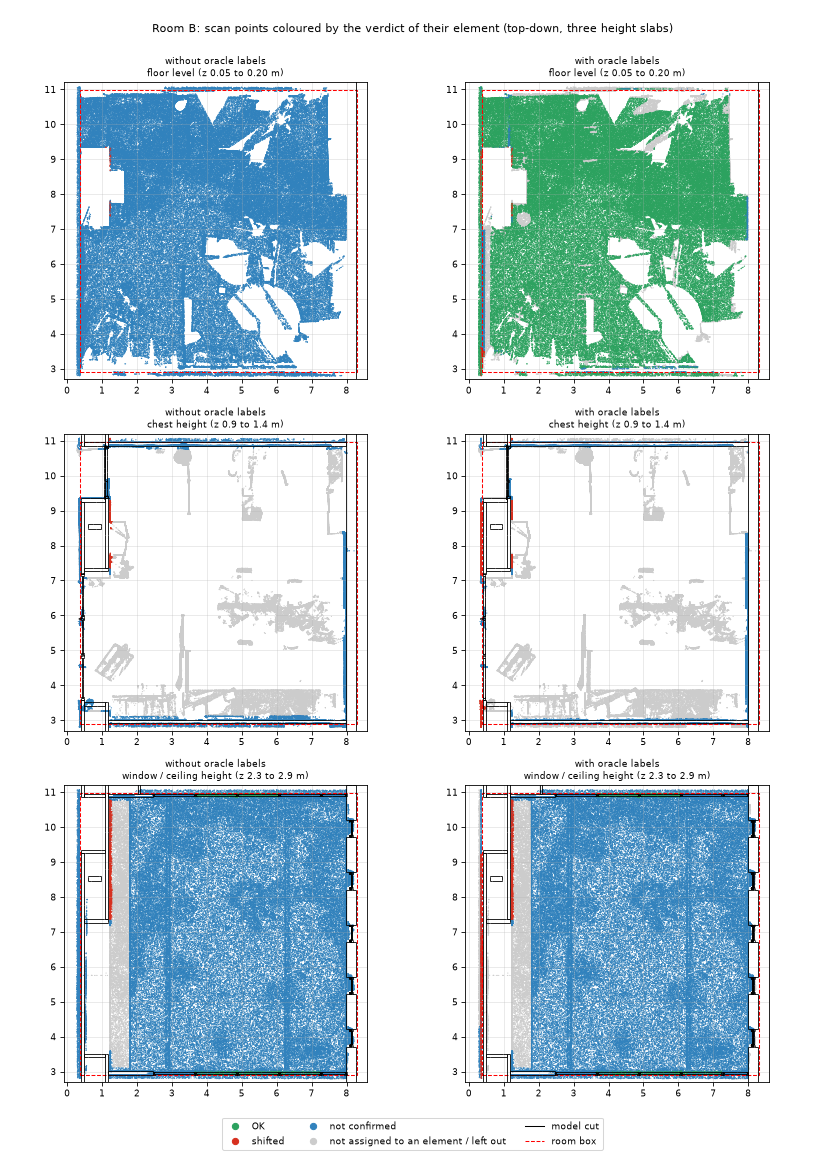

peak RSS 1.43 GB, notebook run 178 s


In [17]:
VERDICT_COLOUR = {"OK": "#2ca25f", "shifted": "#d7301f", "not confirmed": "#3182bd"}
GREY = np.array([0.80, 0.80, 0.80])
rgb = lambda h: np.array([int(h[k:k + 2], 16) / 255 for k in (1, 3, 5)])
SLABS = [("floor level (z 0.05 to 0.20 m)", 0.05, 0.20, 0.05), ("chest height (z 0.9 to 1.4 m)", 0.9, 1.4, 1.15),
         ("window / ceiling height (z 2.3 to 2.9 m)", 2.3, 2.9, 2.5)]  # name, z range, height of the model cut


def section(elements, axis, value):
    # Line segments where the plane axis == value cuts the elements' triangles: (n, 2, 2), two end points in the other two axes.
    keep = [i for i in range(3) if i != axis]
    out = []
    for e in elements:
        v = e.vertices
        if v[:, axis].min() >= value or v[:, axis].max() <= value:
            continue
        tri = v[e.faces]
        s = tri[:, :, axis] - value
        S = np.full((len(tri), 2, 2), np.nan)
        count = np.zeros(len(tri), int)
        for i, j in ((0, 1), (1, 2), (2, 0)):
            idx = np.where(s[:, i] * s[:, j] < 0)[0]
            t = s[idx, i] / (s[idx, i] - s[idx, j])
            S[idx, count[idx]] = tri[idx, i][:, keep] + t[:, None] * (tri[idx, j][:, keep] - tri[idx, i][:, keep])
            count[idx] += 1
        out.append(S[count == 2])
    return np.concatenate(out) if out else np.zeros((0, 2, 2))


rs = np.random.default_rng(SEED)
fig, axs = plt.subplots(3, 2, figsize=(11, 15.4))
for row, (title, z0, z1, z_cut) in enumerate(SLABS):
    slab = np.flatnonzero((P[:, 2] >= z0) & (P[:, 2] <= z1))
    pick = np.sort(rs.choice(slab, min(150_000, len(slab)), replace=False))
    cuts = section(elements, 2, z_cut)
    for col, (rows, use, label) in enumerate(((rows_no_labels, np.ones(len(P), bool), "without oracle labels"),
                                              (rows_oracle, is_element_class, "with oracle labels"))):
        element_colour = np.array([rgb(VERDICT_COLOUR[r["verdict"]]) for r in rows])
        coloured = in_band[pick] & use[pick]
        colour = np.where(coloured[:, None], element_colour[geom_id[pick]], GREY)
        order = np.argsort(coloured, kind="stable")  # grey first, verdict colours on top
        ax = axs[row, col]
        ax.scatter(P[pick[order], 0], P[pick[order], 1], s=1.2, c=colour[order], linewidths=0, rasterized=True)
        ax.add_collection(LineCollection(cuts, colors="k", linewidths=0.8))
        ax.add_patch(plt.Rectangle(box_lo[:2], *(box_hi - box_lo)[:2], fill=False, ec="r", ls="--", lw=1))
        ax.set_xlim(-0.1, 8.6); ax.set_ylim(2.7, 11.2); ax.set_aspect("equal"); ax.grid(alpha=0.3)
        ax.set_title(f"{label}\n{title}", fontsize=9)
fig.legend(handles=[plt.Line2D([], [], marker="o", ls="", ms=6, color=c, label=v) for v, c in VERDICT_COLOUR.items()] +
           [plt.Line2D([], [], marker="o", ls="", ms=6, color=GREY, label="not assigned to an element / left out"),
            plt.Line2D([], [], color="k", lw=1, label="model cut"), plt.Line2D([], [], color="r", ls="--", lw=1, label="room box")],
           loc="lower center", ncol=3, fontsize=9)
fig.suptitle("Room B: scan points coloured by the verdict of their element (top-down, three height slabs)")
plt.tight_layout(rect=(0, 0.04, 1, 0.98))
fig.savefig(OUT / "verdicts_top_down.png", dpi=75)  # 825 x 1155 px: under 1200 in both dimensions, and a smaller notebook
plt.close(fig)
display(Image(filename=str(OUT / "verdicts_top_down.png"), width=825))
print(f"peak RSS {peak_rss_gb():.2f} GB, notebook run {time.time() - T0:.0f} s")


## Answer

Room B of the CRAS lab, 35 elements, USIBD LOA30 (15 mm at 2 sigma, so 95 % of an element's points within 15 mm for OK), one transform (refined from 01's, no labels) for both runs.

**Verdicts.** Without oracle labels: **5 OK, 1 shifted, 29 not confirmed**. With oracle labels: **6 OK, 2 shifted, 27 not confirmed**. Missing and not visible do not occur: 01 recovered no scanner positions (1 of 21, outside the box), so that branch is not implemented. OK needs 95 % of the points within 15 mm (`MIN_FRAC_OK`, LOA30's confidence level); shifted needs `|median| > 15 mm` and `MIN_FRAC_CLUSTER` = 80 % of the points within 15 mm of the median, a judgement call that is not from the standard. The sliver rule moves 2 coverings from OK to not confirmed (under 1 % of their surface in the box, OK on a 10 cm strip). Walls are measured against their room-facing faces; with the nearest-face offsets that this notebook used before, the counts were 5 / 3 / 27 without labels and 7 / 5 / 23 with, and only walls differ between the two.

- **OK (5 without labels):** five windows, with median offsets within 0.3 mm and 95 to 98 % of their points inside 15 mm. With labels one more: the floor slab (98 % inside 15 mm with labels, 88 % without). The wall `Drywall:9732` was OK with labels under the nearest-face rule (96 %); it is not now (59 %), see below.
- **Shifted (1 without labels, 2 with):** without labels only `Drywall:9790`, a long wall with 50 % of its surface in the box, at **+49.5 mm** (85 % of its 59,804 points within 15 mm of the median); with labels the same at +49.1 mm (94 %) and the **thin west wall** `Drywall:9625` at **-134.6 mm** (81 % within 15 mm of the median; 70 % without labels, so not shifted there, though its median is -134.3 mm either way). Its scan surface (median x 0.356 m) is 13.4 cm behind the modelled room-facing face at x 0.49 m and 3.4 cm behind even the modelled outer face; the nearest-face rule read +35 mm. Four walls that the nearest-face rule called shifted or OK, or near it, are not confirmed now: `Drywall:9615` and `Drywall:9732` (medians 4.8 -> -102.5 mm and 0.4 -> -7.4 mm: 39 % and 37 % of their points are on the outer surface, one wall thickness behind the room-facing face; `Drywall:9732` was OK with labels), `Drywall:9767` (+40.7 -> -80.3 mm, 12 % near the median) and `Drywall:9786` (+54.1 -> +55.0 mm, now 72 % near the median, 78 % with labels, just short of the 80 % line). `Drywall:9773` (-1.0 -> -2.6 mm without labels, 77 % within 15 mm) was shifted at +37.8 mm with labels and reads -44.0 mm now (77 % near the median, 5,469 points); I did not check it, but its points may be the displaced west-wall surface seen past the end of this short wall, whose edge sets the offset there. I did not look into why `Drywall:9790` and `Drywall:9786` sit at +50 to +55 mm (finish layers missing from the model, or a real displacement); the scan alone does not say. `Drywall:9768` (+94.8 mm with labels, 2,394 points) is bimodal (47 % within 15 mm of zero, 53 % within 15 mm of its median), so it is not one cluster. At the strict 95 % cluster share none is shifted (sensitivity table in section 4).
- **Not confirmed (29 without labels, 27 with):** without labels, 22 are "inconsistent offsets" (9 walls, 10 windows, the door, the floor slab and the ceiling covering), 5 are "mostly outside the room box" (four coverings and one wall with 0 to 9 % of their surface in the box) and 2 are "too few points" (the column, 78 points within 10 cm, none with labels: the scan holds almost nothing there, and without scanner positions that cannot be called missing or not visible; and a window with 1,965 points, 35 short of `MIN_POINTS`). With labels: 19 inconsistent (7 walls, 10 windows, the door, the ceiling covering), 5 outside the box, 3 too few points (the same two and a wall with 76 points once the clutter is removed). Many of the "inconsistent offsets" are near misses of the 95 % line, not scattered: the ceiling covering 92 %, the slab 88 % (without labels), windows at 87 to 93 %, two walls at 77 and 81 % (without labels). At 80 % the OK count is 13 without labels and 13 with.
- **With vs without labels:** 2 elements change, both from not confirmed: the floor slab (`Floor:(15cm) Piso + Porcelanato`, 696,945 points without labels, 594,879 with) becomes OK and the west wall `Drywall:9625` (148,667 and 127,466 points, -134.3 and -134.6 mm) becomes shifted. The only difference between the runs is the points, so the cause is clutter and unassigned points within 10 cm of these elements: they add other offsets and pull the share within 15 mm from 88 to 98 % for the slab and the share near the median from 70 to 81 % for the west wall. The other 33 verdicts agree. That 2 of 35 move is an upper bound on what segmentation is worth in this room (it was 4 under the nearest-face rule).

**Frame.** The coarse check does not confirm the recorded transform and does not refute it. RANSAC is the coarse step of 02's method; run here, in the as-delivered frame, on this room it failed: FPFH + RANSAC lands within 2 degrees and 5 cm of the recorded transform on **0 of 5** seeds (rotations of 79 to 172 degrees, room centroid 0.3 to 1.2 m off), which is what a cluttered, nearly box-shaped room does to it (02 saw the same on UVigo). So RANSAC did not provide the starting point here: the recorded transform from 01 (itself a coarse FFT step plus ICP) is what ICP refines. ICP started from it stays where it is: the correction is **0.11 degrees and 6.8 mm** at the room centroid (sanity bounds 0.5 degrees and 5 cm), and refining on oracle-label points only differs from the no-label refinement by 0.009 degrees and 0.3 mm. Registration residual after refinement for the element-class points in the box: median 5.4 mm, p90 40 mm, p99 247 mm (floor: p99 12 mm).

**01's p99 tail.** 5.0 % of the element-class points in the box (114,247) lie more than 10 cm from every element, which is what makes the in-room p99 247 mm (wall class alone: p99 371 mm; ceiling 247 mm, door 124 mm, window 116 mm, floor 12 mm). They sit in four places, each a real surface the model lacks or puts elsewhere: ceiling-class points at z 2.55 to 2.66 m along x 1.3 to 1.8 m (10 % of the ceiling class, median 0.24 m from the nearest element, which is a covering for 87 % of them); wall-class points at x about 1.23 m, y 3.8 to 7.2 m, median z 2.36 m, where the model's 10 cm wall at x 1.08 to 1.18 m has a gap (y 3.51 to 7.36 m); door-class points in a line at y 10.75 m, 11 cm from the nearest wall face (a wall for 99 % of them), which the one modelled door (at x 1.0 to 1.2 m) does not explain; and window-class points at x about 7.97 m, z 2.5 to 2.7 m, 13 cm in front of the glazing (a blind box or reveal, probably). So the residual tail is unmodelled or differently modelled geometry, not a registration failure (the median is 5.4 mm and the floor's p99 is 12 mm); I did not check the IFC or the scan further to say which of the two it is at each place. 01's 0.48 m (p99 after its ICP: 0.481 m) was measured differently: on 200,000 wall-class scan points sampled over the whole lab, against model walls and columns only (not doors, windows or coverings). So this room shows the same kind of cause, not that exact number.

**Triangle winding.** All 35 elements are outward-facing: walls, slab, column and coverings are closed solids (outward share 1.00), windows and doors are unions of overlapping solids (outward share 0.67 to 0.90, inward at most 0.23), so no element was flipped.

**Partly-inside elements.** 11 of the 35 cross a box face, and their verdicts cover only the part the cropped scan reaches: without labels none is OK, 1 is shifted (`Drywall:9790`, 50 % of its surface in the box) and 10 are not confirmed (5 of them by the sliver rule); with labels the floor slab is OK, 2 are shifted (`Drywall:9790` and the west wall) and 8 are not confirmed (5 by the sliver rule). The strict box (no padding) gives 6 OK, 1 shifted, 28 not confirmed against 5 / 1 / 29 padded: one element changes, `Drywall:9773` (OK strict with 22,741 points, not confirmed padded with 29,000 points at 77 % within 15 mm), because the padding admits points beyond the box. The padding is kept because a box face can lie on a wall's surface: 83 % of the thin west wall's band points lie outside the box, whose west face is 1 cm outside the wall, so the strict crop would judge it on the remaining 25,652 of its 148,667 points. Verdicts of walls that lie on a box face are sensitive to the crop; a box whose faces sit on wall centre lines (or per-element surface patches) would be cleaner than either.

**Judgement calls.** `MIN_POINTS` between 200 and 2,000 changes nothing; 20,000 would leave 0 OK, 1 shifted and 34 not confirmed without labels (1 / 2 / 32 with labels). `MIN_FRAC_OK` carries the OK count: 0.95 (LOA30's confidence level) gives 5 / 1 / 29 without labels and 6 / 2 / 27 with; 0.8 (00's) gives 13 / 1 / 21 and 13 / 2 / 20. `MIN_FRAC_CLUSTER` carries the shifted count and is not from the standard: 0.95 gives 0 shifted in both runs (5 / 0 / 30 and 6 / 0 / 29), 0.8 gives 1 and 2, and 0.7 or 0.6 give 3 and 4 (without labels the west wall at 70 % and `Drywall:9786` at 72 %; with labels `Drywall:9786` and `Drywall:9773`, at 78 and 77 %). The synthetic 55 / 45 bimodal case is rejected at 0.8 but would pass at 0.55, so the value should not go much lower. `MIN_AREA_IN_BOX` (10 %) is a judgement call; it moves 2 elements, both OK on a 10 cm strip. `PROBE` (5 cm) only decides which faces of a wall are room-facing; I did not vary it.
